In [11]:
from sympy import *
init_printing(use_unicode=True)

In [12]:
F00, F01, F10, F11 = symbols('F00 F01 F10 F11')
F = Matrix([[F00, F01], [F10, F11]])
F_vec = Matrix([F00, F01, F10, F11])
F_sqnorm = F00 ** 2 + F01 ** 2 + F10 ** 2 + F11 ** 2
mu, lam = symbols('self.μ self.λ')

# Neohookean

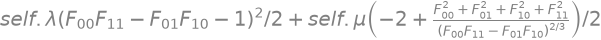

In [13]:
Psi = Rational(1, 2) * (mu * (F.det() ** Rational(-2, 3) * (F.T * F).trace() - 2) + lam * (F.det() - 1) ** 2)
Psi

In [14]:
g = diff(Psi, F_vec)
for i in range(4):
    print(f'g[{i}] =', pycode(g[i]))

g[0] = F11*self.λ*(F00*F11 - F01*F10 - 1) + (1/2)*self.μ*(2*F00/(F00*F11 - F01*F10)**(2/3) - 2/3*F11*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(5/3))
g[1] = -F10*self.λ*(F00*F11 - F01*F10 - 1) + (1/2)*self.μ*(2*F01/(F00*F11 - F01*F10)**(2/3) + (2/3)*F10*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(5/3))
g[2] = -F01*self.λ*(F00*F11 - F01*F10 - 1) + (1/2)*self.μ*((2/3)*F01*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(5/3) + 2*F10/(F00*F11 - F01*F10)**(2/3))
g[3] = F00*self.λ*(F00*F11 - F01*F10 - 1) + (1/2)*self.μ*(-2/3*F00*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(5/3) + 2*F11/(F00*F11 - F01*F10)**(2/3))


In [15]:
H = hessian(Psi, F_vec)
for i in range(4):
    for j in range(4):
        print(f'H[{i}, {j}] =', pycode(H[i, j]))

H[0, 0] = F11**2*self.λ + (1/2)*self.μ*(-8/3*F00*F11/(F00*F11 - F01*F10)**(5/3) + (10/9)*F11**2*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(8/3) + 2/(F00*F11 - F01*F10)**(2/3))
H[0, 1] = -F10*F11*self.λ + (1/2)*self.μ*((4/3)*F00*F10/(F00*F11 - F01*F10)**(5/3) - 4/3*F01*F11/(F00*F11 - F01*F10)**(5/3) - 10/9*F10*F11*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(8/3))
H[0, 2] = -F01*F11*self.λ + (1/2)*self.μ*((4/3)*F00*F01/(F00*F11 - F01*F10)**(5/3) - 10/9*F01*F11*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(8/3) - 4/3*F10*F11/(F00*F11 - F01*F10)**(5/3))
H[0, 3] = F00*F11*self.λ + self.λ*(F00*F11 - F01*F10 - 1) + (1/2)*self.μ*(-4/3*F00**2/(F00*F11 - F01*F10)**(5/3) + (10/9)*F00*F11*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(8/3) - 4/3*F11**2/(F00*F11 - F01*F10)**(5/3) - 2/3*(F00**2 + F01**2 + F10**2 + F11**2)/(F00*F11 - F01*F10)**(5/3))
H[1, 0] = -F10*F11*self.λ + (1/2)*self.μ*((4/3)*F00*F10/(F00*F11 - F01*F10)**(5/3) - 4/3*F01*F11/(F0

# Linear elasticity

In [16]:
ep = Rational(1, 2) * (F.T * F - eye(2))

Psi_lin = mu * trace(ep.T * ep) + lam * trace(ep) ** 2

In [17]:
g = diff(Psi_lin, F_vec)
for i in range(4):
    print(f'g[{i}] =', pycode(g[i]))

g[0] = 2*F00*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(2*F00*((1/2)*F00**2 + (1/2)*F10**2 - 1/2) + 2*F01*((1/2)*F00*F01 + (1/2)*F10*F11))
g[1] = 2*F01*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(2*F00*((1/2)*F00*F01 + (1/2)*F10*F11) + 2*F01*((1/2)*F01**2 + (1/2)*F11**2 - 1/2))
g[2] = 2*F10*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(2*F10*((1/2)*F00**2 + (1/2)*F10**2 - 1/2) + 2*F11*((1/2)*F00*F01 + (1/2)*F10*F11))
g[3] = 2*F11*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(2*F10*((1/2)*F00*F01 + (1/2)*F10*F11) + 2*F11*((1/2)*F01**2 + (1/2)*F11**2 - 1/2))


In [18]:
H = hessian(Psi_lin, F_vec)
for i in range(4):
    for j in range(4):
        print(f'H[{i}, {j}] =', pycode(H[i, j]))

H[0, 0] = 2*F00**2*self.λ + 2*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(3*F00**2 + F01**2 + F10**2 - 1)
H[0, 1] = 2*F00*F01*self.λ + self.μ*(2*F00*F01 + F10*F11)
H[0, 2] = 2*F00*F10*self.λ + self.μ*(2*F00*F10 + F01*F11)
H[0, 3] = 2*F00*F11*self.λ + F01*F10*self.μ
H[1, 0] = 2*F00*F01*self.λ + self.μ*(2*F00*F01 + F10*F11)
H[1, 1] = 2*F01**2*self.λ + 2*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(F00**2 + 3*F01**2 + F11**2 - 1)
H[1, 2] = F00*F11*self.μ + 2*F01*F10*self.λ
H[1, 3] = 2*F01*F11*self.λ + self.μ*(F00*F10 + 2*F01*F11)
H[2, 0] = 2*F00*F10*self.λ + self.μ*(2*F00*F10 + F01*F11)
H[2, 1] = F00*F11*self.μ + 2*F01*F10*self.λ
H[2, 2] = 2*F10**2*self.λ + 2*self.λ*((1/2)*F00**2 + (1/2)*F01**2 + (1/2)*F10**2 + (1/2)*F11**2 - 1) + self.μ*(F00**2 + 3*F10**2 + F11**2 - 1)
H[2, 3] = 2*F10*F11*self.λ + self.μ*(F00*F01 + 2*F10*F11)
H[3, 0] = 2*F00*F11*self.λ + F01*F10*self.μ
H[3, 1] = 2*F01*F11*self.λ + self.μ*(F00*F10 + 